# UniFeedback
### An NLP System for Analyzing Student Feedback on University Services

University members — students, staff, and faculty — face many issues with university services, such as registration system failures, late buses, weak Wi-Fi, and broken facilities. Many universities lack an easy, fast channel for reporting these issues, or a clear unit that collects and analyzes them. Feedback also arrives in large volumes, in Arabic and English, and in both Modern Standard Arabic and dialect, which makes manual review slow and causes important issues to be missed.

UniFeedback addresses this by analyzing feedback automatically using Transformer models:

| Stage | Description | Source |
|---|---|---|
| 1 | Text cleaning and personal data (PII) masking | Lab 1 |
| 2 | Understanding words in context through attention | Lab 2 |
| 3 | Classifying feedback by topic: registration, transport, Wi-Fi, facilities | Lab 3A |
| 4 | Handling Arabic features: clitics, letter normalization, dialects | Lab 3B, Lab 4 |
| 5 | Bilingual semantic search for similar feedback | Lab 5 |
| 6 | Sliced evaluation and error analysis | Lab 6 |
| 7 | Demo: classification, topic chart, similar-feedback search | — |
| 8 | Interactive web demo (Gradio) | — |

**How to run:** Runtime → Change runtime type → T4 GPU, then Runtime → Run all.

## 0. Setup
Install and import the required libraries once for the whole project.

In [1]:
# 🧪 Setup: Installation & Imports
!pip install -q transformers datasets scikit-learn pandas matplotlib sentence-transformers faiss-cpu

import pandas as pd
import re
import torch
import matplotlib.pyplot as plt
from transformers import AutoTokenizer

pd.set_option("display.max_colwidth", None)   # Show full text in all tables
project_name = "UniFeedback"
print("✅ Setup Ready —", project_name)

✅ Setup Ready — UniFeedback


## 1. Text Cleaning & Privacy Protection (Lab 1)
- **Data:** 8 feedback samples (4 Arabic, 4 English) that include extra spaces and repeated letters (e.g. "يوووم") to simulate real-world writing.
- **Normalisation:** removes extra spaces and repeated letters.
- **PII Masking:** replaces phone numbers with `[PHONE]` and emails with `[EMAIL]` to protect privacy, in line with Saudi Arabia's Personal Data Protection Law (PDPL).

In [2]:
# 🧪 Lab 1 — Code 3: Create Dataset

# 🏷️ Project Name
project_name = "UniFeedback"

# 📝 Project Dataset
data = {
    "language": ["ar", "ar", "ar", "ar", "en", "en", "en", "en"],
    "text": [
        "  نظام   التسجيل   يعلق   وقت   تسجيل المواد  ",
        "المكتبة    هادئة   والموظفين   متعاونين",
        "  الباص   يتأخر   كل يوووم   عن المحاضرة الأولى  ",
        "  أكل   الكافتيريا   غالي   ومو صحي  ",
        "  The   student portal    is very slow  ",
        "Library    staff were   really helpful",
        "  I cannot   register for    my courses  ",
        "  The   campus Wi-Fi    keeps disconnecting  "
    ]
}

# 📊 Create DataFrame
df = pd.DataFrame(data)

# ✅ Confirmation
print("🧪 Project:", project_name)
print("✅ Dataset created successfully!")

# 📊 Display Dataset
display(df)

🧪 Project: UniFeedback
✅ Dataset created successfully!


,language,text
0,ar,نظام التسجيل يعلق وقت تسجيل المواد
1,ar,المكتبة هادئة والموظفين متعاونين
2,ar,الباص يتأخر كل يوووم عن المحاضرة الأولى
3,ar,أكل الكافتيريا غالي ومو صحي
4,en,The student portal is very slow
5,en,Library staff were really helpful
6,en,I cannot register for my courses
7,en,The campus Wi-Fi keeps disconnecting


In [3]:
# 🧪 Lab 1 — Code 4: Text Normalisation
import re
from IPython.display import HTML, display

def normalize(text):
    text = re.sub(r"(.)\1{2,}", r"\1", str(text))   # Remove repeated letters
    return re.sub(r"\s+", " ", text).strip()        # Remove extra spaces

df["clean_text"] = df["text"].apply(normalize)

print("✅ Normalisation Completed!")
display(HTML(df[["text", "clean_text"]].to_html(index=False)))

✅ Normalisation Completed!


text,clean_text
نظام التسجيل يعلق وقت تسجيل المواد,نظام التسجيل يعلق وقت تسجيل المواد
المكتبة هادئة والموظفين متعاونين,المكتبة هادئة والموظفين متعاونين
الباص يتأخر كل يوووم عن المحاضرة الأولى,الباص يتأخر كل يوم عن المحاضرة الأولى
أكل الكافتيريا غالي ومو صحي,أكل الكافتيريا غالي ومو صحي
The student portal is very slow,The student portal is very slow
Library staff were really helpful,Library staff were really helpful
I cannot register for my courses,I cannot register for my courses
The campus Wi-Fi keeps disconnecting,The campus Wi-Fi keeps disconnecting


In [4]:
# 🧪 Lab 1 — Code 5: PII Masking

# 📝 Add Sample Personal Information
df.loc[0, "clean_text"] = (
    "نظام التسجيل يعلق وقت تسجيل المواد تواصلوا معي على "
    "0551234567 أو student@uni.edu.sa"
)

df.loc[2, "clean_text"] = (
    "الباص يتأخر كل يوم عن المحاضرة الأولى "
    "راسلوني على sara.ahmed@gmail.com أو 0509876543"
)

df.loc[4, "clean_text"] = (
    "The student portal is very slow "
    "please contact me at 0567891234"
)

df.loc[6, "clean_text"] = (
    "I cannot register for my courses "
    "email me at reem.ali@outlook.com or call 0531112233"
)

# 🛡️ Define Masking Function
def mask_pii(text):
    text = str(text)

    # Mask Email Addresses
    text = re.sub(r'\b[\w.+-]+@[\w.-]+\.[A-Za-z]{2,}\b', '[EMAIL]', text)

    # Mask Saudi Mobile Numbers
    text = re.sub(r'\b05\d{8}\b', '[PHONE]', text)

    return text

# 🔒 Apply Masking
df["masked_text"] = df["clean_text"].apply(mask_pii)

# 📊 Display Results
display(df[["clean_text", "masked_text"]])

,clean_text,masked_text
0,نظام التسجيل يعلق وقت تسجيل المواد تواصلوا معي على 0551234567 أو student@uni.edu.sa,نظام التسجيل يعلق وقت تسجيل المواد تواصلوا معي على [PHONE] أو [EMAIL]
1,المكتبة هادئة والموظفين متعاونين,المكتبة هادئة والموظفين متعاونين
2,الباص يتأخر كل يوم عن المحاضرة الأولى راسلوني على sara.ahmed@gmail.com أو 0509876543,الباص يتأخر كل يوم عن المحاضرة الأولى راسلوني على [EMAIL] أو [PHONE]
3,أكل الكافتيريا غالي ومو صحي,أكل الكافتيريا غالي ومو صحي
4,The student portal is very slow please contact me at 0567891234,The student portal is very slow please contact me at [PHONE]
5,Library staff were really helpful,Library staff were really helpful
6,I cannot register for my courses email me at reem.ali@outlook.com or call 0531112233,I cannot register for my courses email me at [EMAIL] or call [PHONE]
7,The campus Wi-Fi keeps disconnecting,The campus Wi-Fi keeps disconnecting


## 2. How the Model Understands a Sentence (Lab 2)
- **Attention Map:** runs CAMeLBERT on a sentence from the project data and visualizes how strongly words attend to each other — the darker the color, the stronger the attention.
- **PAD Leak Test:** pads the sentence with empty `[PAD]` tokens and compares the attention they receive with and without the attention mask. With the mask, attention to padding is zero; without it, the model gives padding a large share of its attention — a silent error that raises no warning.

config.json:   0%|          | 0.00/468 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/86.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/305k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  439MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B /  439MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: CAMeL-Lab/bert-base-arabic-camelbert-mix
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


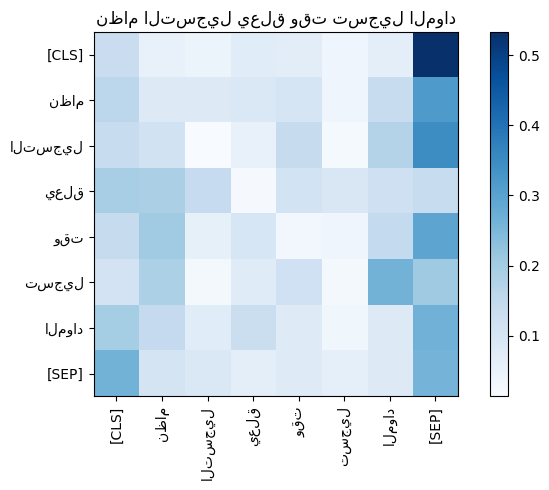

✅ Attention Map Completed!


In [5]:
# 🧪 Lab 2 — Code 6: Attention Maps


from transformers import AutoTokenizer, AutoModel


# 🤖 Load Model

name = "CAMeL-Lab/bert-base-arabic-camelbert-mix"

tok = AutoTokenizer.from_pretrained(name)

model = AutoModel.from_pretrained(

    name, attn_implementation="eager"

).eval()


# ✏️ Change the text here

texts = [
    "نظام التسجيل يعلق وقت تسجيل المواد",
    "المكتبة هادئة والموظفين متعاونين",
    "الباص يتأخر عن المحاضرة الأولى",
    "الواي فاي في الجامعة ضعيف",
    "إضاءة القاعات خافته",
    "المصعد مو شغال كل الوقت"
]
text = texts[0]


# 🧠 Calculate Attention

inputs = tok(text, return_tensors="pt")


with torch.no_grad():

    att = model(**inputs, output_attentions=True).attentions


# 📊 Display Attention Map

tokens = tok.convert_ids_to_tokens(inputs["input_ids"][0])


plt.figure(figsize=(7, 5))

plt.imshow(att[0][0, 0].numpy(), cmap="Blues")

plt.xticks(range(len(tokens)), tokens, rotation=90)

plt.yticks(range(len(tokens)), tokens)

plt.title(text)

plt.colorbar()

plt.tight_layout()

plt.show()


print("✅ Attention Map Completed!")

In [6]:
# 🧪 Lab 2 — Code 7: PAD Leak Detection


# ✏️ Change padding length here

pad_length = 36


# 🔤 Use Text from Code 6

size = max(pad_length, len(tok.encode(text)) + 4)

inputs = tok(text, return_tensors="pt",

             padding="max_length", max_length=size)


# 🧠 Compare With / Without Mask

with torch.no_grad():

    with_mask = model(**inputs, output_attentions=True).attentions[0][0, 0]

    without_mask = model(

        input_ids=inputs["input_ids"], output_attentions=True

    ).attentions[0][0, 0]


# 📊 Display Results

pads = inputs["attention_mask"][0] == 0

valid = ~pads


print("✅ PAD Leak Test Completed!")

print("PAD Count:", pads.sum().item())

print("With Mask:", round(with_mask[valid][:, pads].sum(-1).mean().item(), 4))

print("Without Mask:", round(without_mask[valid][:, pads].sum(-1).mean().item(), 4))

✅ PAD Leak Test Completed!
PAD Count: 28
With Mask: 0.0
Without Mask: 0.5649


## 3. Feedback Classification (Lab 3A)
- **Data:** 40 feedback samples from 20 students, 10 per topic, including Saudi-dialect sentences from Lab 4.
- **Group-based split (GroupShuffleSplit):** all feedback from the same student goes into the same split to prevent data leakage, since one student may write two very similar comments.
- **Model:** CAMeLBERT, an Arabic encoder model, with a new classification head for the 4 topics.
- **Training settings:** `epochs=10`, `batch_size=4`, `learning_rate=5e-5`.
- **Result:** with 16 samples, `eval_loss` was about 1.30 — close to random guessing. After increasing the data to 40 samples, it dropped to 0.11.

In [7]:
# 🧪 Lab 3A — Code 2: Custom Dataset Preparation
import pandas as pd

# بيانات المشروع - يمكن تعديلها
data = {
    "student_id": [1, 1, 2, 2, 3, 3, 4, 4, 5, 5,
                   6, 6, 7, 7, 8, 8, 9, 9, 10, 10,
                   11, 11, 12, 12, 13, 13, 14, 14, 15, 15,
                   16, 16, 17, 17, 18, 18, 19, 19, 20, 20],
    "text": [
        # registration
        "نظام التسجيل يعلق وقت تسجيل المواد",
        "البانر من أمس معلق",
        "ما قدرت أسجل المواد من البوابة",
        "أبغى أسجل في شعبة الصباح",
        "الشعب تقفل بسرعة وقت التسجيل",
        "ليه أغلب الشعب مقفلة",
        "ما فيه مقاعد كافية في المواد الإجبارية",
        "أبي أنزل مادة زيادة",
        "أبي أغير شعبتي",
        "أبي أحذف المادة",
        # transport
        "الباص يتأخر عن المحاضرة الأولى",
        "مواعيد الباصات غير منتظمة",
        "الباص زحمة ومافيه مكان",
        "زيدوا عدد الباصات الترددية",
        "محطة الباص بعيدة عن المباني",
        "ما فيه باص يوصل للسكن بالليل",
        "السواق مشى قبل لا أركب",
        "ننتظر الباص أكثر من نص ساعة",
        "مواقف السيارات دايم زحمة",
        "الباص الترددي يتأخر بين المباني",
        # wifi
        "الواي فاي في الجامعة ضعيف",
        "ما أقدر أتصل بشبكة الجامعة",
        "الإنترنت يفصل كل شوي في القاعات",
        "الانترنت يفصل كل شوي داخل القاعات",
        "الواي فاي بطيء في السكن",
        "التغطية ضعيفة في مبنى الكلية",
        "كلمة مرور الواي فاي ما تشتغل",
        "النت ثقيل مرة في المعامل",
        "ما أقدر أحمل المحاضرات من بطء الشبكة",
        "الواي فاي ينقطع وقت الاختبارات الإلكترونية",
        # facilities
        "دورات المياه مغلقه",
        "دورات المياه مافيها مويه",
        "إضاءة القاعات خافته",
        "اللمبات خافته",
        "المصعد مو شغال كل الوقت",
        "المصاعد خربانه",
        "آلات الطعام معطله",
        "الات الطعام خربانه",
        "المكيف خربان في القاعة",
        "الكراسي مكسورة في المدرج"
    ],
    "topic": ["registration"] * 10 + ["transport"] * 10 + ["wifi"] * 10 + ["facilities"] * 10
}

df = pd.DataFrame(data)

topics = sorted(df["topic"].unique())
label_map = {topic: i for i, topic in enumerate(topics)}
df["label"] = df["topic"].map(label_map)

print(df)
print("\nLabels:", label_map)
print("Total:", len(df), "| Per topic:", df["topic"].value_counts().to_dict())

    student_id                                        text         topic  \
0            1          نظام التسجيل يعلق وقت تسجيل المواد  registration   
1            1                          البانر من أمس معلق  registration   
2            2              ما قدرت أسجل المواد من البوابة  registration   
3            2                    أبغى أسجل في شعبة الصباح  registration   
4            3                الشعب تقفل بسرعة وقت التسجيل  registration   
5            3                        ليه أغلب الشعب مقفلة  registration   
6            4      ما فيه مقاعد كافية في المواد الإجبارية  registration   
7            4                         أبي أنزل مادة زيادة  registration   
8            5                              أبي أغير شعبتي  registration   
9            5                             أبي أحذف المادة  registration   
10           6              الباص يتأخر عن المحاضرة الأولى     transport   
11           6                   مواعيد الباصات غير منتظمة     transport   
12          

In [8]:
# 🧪 Lab 3A — Code 3: GroupShuffleSplit

from sklearn.model_selection import GroupShuffleSplit


# ✏️ يمكن تعديل القيم حسب

test_size = 0.20

random_state = 7

group_column = "student_id"


gss = GroupShuffleSplit(

    n_splits=1,

    test_size=test_size,

    random_state=random_state

)


train_idx, test_idx = next(

    gss.split(df, groups=df[group_column])

)


train_df = df.iloc[train_idx]

test_df = df.iloc[test_idx]


shared = set(train_df[group_column]) & set(test_df[group_column])


print("Train:", len(train_df))

print("Test:", len(test_df))

print("Shared Students:", shared)

Train: 32
Test: 8
Shared Students: set()


In [9]:
# 🧪 Lab 3A — Code 4: Tokenization & Dataset Preparation
from transformers import AutoTokenizer
from datasets import Dataset

tokenizer = AutoTokenizer.from_pretrained("CAMeL-Lab/bert-base-arabic-camelbert-mix")

sample_texts = ["نظام التسجيل يعلق وقت تسجيل المواد",
                "ماقدرت اسجل المواد من البوابه"]


def prepare_data(data):
    tokens = tokenizer(data["text"].tolist(), padding=True, truncation=True)
    tokens["labels"] = data["label"].tolist()
    return Dataset.from_dict(tokens)


train_dataset = prepare_data(train_df)
test_dataset = prepare_data(test_df)


for sample in sample_texts:
    print("Text:", sample)
    print("Tokens:", tokenizer.tokenize(sample))
    print("Input IDs:", tokenizer.encode(sample))
    print()

print("✅ Dataset Ready!")
print("Train:", len(train_dataset), "| Test:", len(test_dataset))

Text: نظام التسجيل يعلق وقت تسجيل المواد
Tokens: ['نظام', 'التسجيل', 'يعلق', 'وقت', 'تسجيل', 'المواد']
Input IDs: [2, 3701, 4441, 22713, 2758, 6131, 4989, 3]

Text: ماقدرت اسجل المواد من البوابه
Tokens: ['ماقد', '##رت', 'اس', '##جل', 'المواد', 'من', 'البوا', '##به']
Input IDs: [2, 23565, 2148, 2171, 2293, 4989, 1908, 7712, 2204, 3]

✅ Dataset Ready!
Train: 32 | Test: 8


In [10]:
# 🧪 Lab 3A — Code 5: Load Model

from transformers import AutoModelForSequenceClassification


num_labels = len(topics)


model = AutoModelForSequenceClassification.from_pretrained(

    "CAMeL-Lab/bert-base-arabic-camelbert-mix",

    num_labels=num_labels

)


print("✅ Model Ready!")

print("Number of Labels:", num_labels)

print("Topics:", topics)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: CAMeL-Lab/bert-base-arabic-camelbert-mix
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSIN

✅ Model Ready!
Number of Labels: 4
Topics: ['facilities', 'registration', 'transport', 'wifi']


In [11]:
# 🧪 Lab 3A — Code 6: Model Training & Evaluation

from transformers import TrainingArguments, Trainer


epochs = 10

batch_size = 4

learning_rate = 5e-5


args = TrainingArguments(

    output_dir="./results",

    num_train_epochs=epochs,

    per_device_train_batch_size=batch_size,

    learning_rate=learning_rate,

    report_to="none"

)


trainer = Trainer(

    model=model,

    args=args,

    train_dataset=train_dataset,

    eval_dataset=test_dataset

)


trainer.train()

print("✅ Training Complete!")

print(trainer.evaluate())

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Step,Training Loss


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

✅ Training Complete!


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Training Loss,Validation Loss,Step
No log,0.107792,80


{'eval_loss': 0.10779209434986115}


## 4. Arabic Language Features (Lab 3B, Lab 4)
- **Clitics:** words such as "والمكتبة" and "بالقاعة" are split into several tokens because Arabic attaches letters to words.
- **Letter normalization:** (أ، إ، آ) → (ا), (ى) → (ي), (ة) → (ه), so that "مغلقة" and "مغلقه" are treated as the same word.
- **Dialect Audit:** the same meaning written in MSA and in dialect. Models trained mainly on MSA silently lose accuracy on dialect, so the data must be understood before choosing a model.

In [12]:
# 🧪 Lab 3B — Code 3: Arabic Clitic-Splitting

words = ["والمكتبة", "بالقاعة", "وللمصعد"]


tokens = tokenizer(words, is_split_into_words=True)


token_list = tokenizer.convert_ids_to_tokens(tokens["input_ids"])


for token, word_id in zip(token_list, tokens.word_ids()):

    print(token, "→", word_id)

[CLS] → None
والمك → 0
##تبة → 0
بالق → 1
##اعة → 1
وللم → 2
##ص → 2
##عد → 2
[SEP] → None


In [13]:
# 🧪 Lab 4 — Code 1: Arabic Normalization

import re

def normalize_arabic(text):
    text = re.sub(r"[إأآا]", "ا", text)
    text = re.sub(r"ى", "ي", text)
    text = re.sub(r"ة", "ه", text)
    return text

texts = ["لا يوجد مقاعد كافية في المواد الإجبارية",
         "أريد التسجيل في شعبة الصباح"]

for text in texts:
    print("Before:", text)
    print("After :", normalize_arabic(text))
    print()

Before: لا يوجد مقاعد كافية في المواد الإجبارية
After : لا يوجد مقاعد كافيه في المواد الاجباريه

Before: أريد التسجيل في شعبة الصباح
After : اريد التسجيل في شعبه الصباح



In [14]:
# 🧪 Lab 4 — Code 2: Dialect Audit

texts = [

    "أريد التسجيل في شعبة الصباح",

    "ابغى اسجل في الشعبة الصباحية",

    "بسجل بالشعبه حقت الصباح"

]


for text in texts:

    print(text)

أريد التسجيل في شعبة الصباح
ابغى اسجل في الشعبة الصباحية
بسجل بالشعبه حقت الصباح


## 5. Bilingual Semantic Search (Lab 5)
- **Idea:** search by meaning, not by keywords. A multilingual model places sentences with similar meanings close together, even across languages.
- **Result:** the English query *"The bus is always late"* returned the Arabic feedback "الباص يتأخر عن المحاضرة الأولى" as the top result — without any translation.

In [15]:
# 🧪 Lab 5 — Code 1: Build FAISS Index

from sentence_transformers import SentenceTransformer

import faiss


texts = [
    "الباص يتأخر عن المحاضرة الأولى",
    "الواي فاي في الجامعة ضعيف",
    "نظام التسجيل يعلق وقت تسجيل المواد",
    "المصعد مو شغال كل الوقت",
    "The library closes too early"
]

search_model = SentenceTransformer(

    "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2"

)


embeddings = search_model.encode(texts)


index = faiss.IndexFlatL2(embeddings.shape[1])


index.add(embeddings)


print("عدد النصوص في FAISS:", index.ntotal)

modules.json:   0%|          | 0.00/229 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/122 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/3.89k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/645 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  471MB            

... (4 outputs left out)

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

عدد النصوص في FAISS: 5


In [16]:
# 🧪 Lab 5 — Code 2: Semantic Search

query = "The bus is always late"


query_embedding = search_model.encode([query])


distances, indices = index.search(query_embedding, 3)


print("Query:", query)

print("Results:")


for i in indices[0]:

    print("-", texts[i])

Query: The bus is always late
Results:
- الباص يتأخر عن المحاضرة الأولى
- نظام التسجيل يعلق وقت تسجيل المواد
- المصعد مو شغال كل الوقت


## 6. Evaluation & Error Analysis (Lab 6)
- **Sliced Evaluation:** results are broken down by language, dialect, and length, because a single overall score can hide weaknesses on dialect.
- **Error Analysis:** errors are grouped by cause, such as two similar topics ("البوابة") or an out-of-scope question ("وش أفضل مطعم؟"), and each type needs a different fix.

*The examples in this section are illustrative of the evaluation method.*

In [17]:
# 🧪 Lab 6 — Code 1: Sliced Evaluation

students = [
    {"language": "Arabic", "dialect": "Saudi", "length": "Short", "correct": 1},
    {"language": "Arabic", "dialect": "Saudi", "length": "Long", "correct": 0},
    {"language": "Arabic", "dialect": "MSA", "length": "Short", "correct": 1},
    {"language": "Arabic", "dialect": "MSA", "length": "Long", "correct": 1},
    {"language": "Arabic", "dialect": "Egyptian", "length": "Short", "correct": 0},
    {"language": "English", "dialect": "Standard", "length": "Short", "correct": 1},
    {"language": "English", "dialect": "Standard", "length": "Long", "correct": 1}
]


for student in students:

    print(

        student["language"],

        "|", student["dialect"],

        "|", student["length"],

        "| Correct:", student["correct"]

    )

Arabic | Saudi | Short | Correct: 1
Arabic | Saudi | Long | Correct: 0
Arabic | MSA | Short | Correct: 1
Arabic | MSA | Long | Correct: 1
Arabic | Egyptian | Short | Correct: 0
English | Standard | Short | Correct: 1
English | Standard | Long | Correct: 1


In [18]:
# 🧪 Lab 6 — Code 3: Error Analysis

errors = [
    ("النت خربان في المكتبة", "واي فاي", "واي فاي"),
    ("الباص ما جا اليوم", "مواصلات", "مواصلات"),
    ("ما قدرت أفتح البوابة", "تسجيل", "واي فاي"),
    ("وش أفضل مطعم قريب من الجامعة؟", "خارج النطاق", "مرافق")
]

for text, actual, predicted in errors:

    print("البلاغ:", text)

    print("التصنيف الصحيح:", actual)

    print("توقع النموذج:", predicted)

    print("التقييم:", "صحيح" if actual == predicted else "خطأ")

    print("-" * 30)

البلاغ: النت خربان في المكتبة
التصنيف الصحيح: واي فاي
توقع النموذج: واي فاي
التقييم: صحيح
------------------------------
البلاغ: الباص ما جا اليوم
التصنيف الصحيح: مواصلات
توقع النموذج: مواصلات
التقييم: صحيح
------------------------------
البلاغ: ما قدرت أفتح البوابة
التصنيف الصحيح: تسجيل
توقع النموذج: واي فاي
التقييم: خطأ
------------------------------
البلاغ: وش أفضل مطعم قريب من الجامعة؟
التصنيف الصحيح: خارج النطاق
توقع النموذج: مرافق
التقييم: خطأ
------------------------------


## 7. Demo
1. Feed the system new feedback it has never seen during training.
2. Classify each piece of feedback by topic.
3. Plot a chart showing how many comments fall under each topic, to identify the most frequent problems.
4. Search for similar feedback in the data, including searching in English.

The feedback list and the search query in the next cell can be edited and re-run.

🏷️ Predicted Topics:


,feedback,predicted_topic
0,الباص ما جا اليوم,transport
1,الباصات زحمة الصبح,transport
2,السواق ما وقف عند المحطة,transport
3,النت مقطوع في السكن,wifi
4,الواي فاي ما يشتغل في القاعة,wifi
5,ما قدرت أسجل المادة,registration
6,المكيف ما يبرد في المعمل,facilities


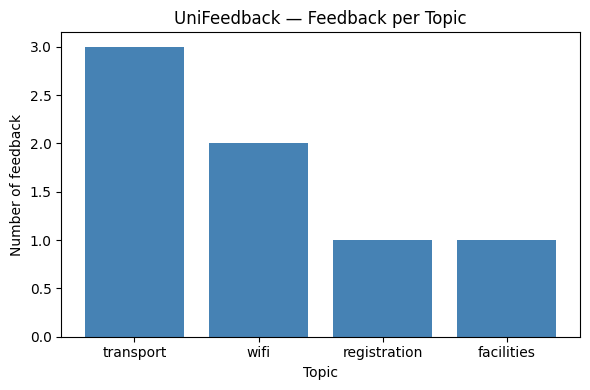

🔎 Query: The bus is always late
Similar feedback:
- الباص الترددي يتأخر بين المباني
- مواعيد الباصات غير منتظمة
- الباص زحمة ومافيه مكان

✅ Demo Completed!


In [19]:
# 🎬 Demo — UniFeedback in Action
import faiss

model.eval()
id2label = {i: t for t, i in label_map.items()}

# ✏️ Change the feedback here
new_feedback = [
    "الباص ما جا اليوم",
    "الباصات زحمة الصبح",
    "السواق ما وقف عند المحطة",
    "النت مقطوع في السكن",
    "الواي فاي ما يشتغل في القاعة",
    "ما قدرت أسجل المادة",
    "المكيف ما يبرد في المعمل"
]


# 1) Classify each feedback
def predict_topic(text):
    inputs = tokenizer(text, return_tensors="pt", truncation=True).to(model.device)
    with torch.no_grad():
        pred = model(**inputs).logits.argmax(-1).item()
    return id2label[pred]

results_df = pd.DataFrame({
    "feedback": new_feedback,
    "predicted_topic": [predict_topic(t) for t in new_feedback]
})
print("🏷️ Predicted Topics:")
display(results_df)


# 2) Chart: which topic has the most feedback?
counts = results_df["predicted_topic"].value_counts()

plt.figure(figsize=(6, 4))
plt.bar(counts.index, counts.values, color="steelblue")
plt.title("UniFeedback — Feedback per Topic")
plt.xlabel("Topic")
plt.ylabel("Number of feedback")
plt.tight_layout()
plt.show()


# 3) Find similar feedback (bilingual semantic search)
# ✏️ Change the search query here
query = "The bus is always late"

all_feedback = df["text"].tolist()
feedback_embeddings = search_model.encode(all_feedback)
demo_index = faiss.IndexFlatL2(feedback_embeddings.shape[1])
demo_index.add(feedback_embeddings)

_, idx = demo_index.search(search_model.encode([query]), 3)

print("🔎 Query:", query)
print("Similar feedback:")
for i in idx[0]:
    print("-", all_feedback[i])

print("\n✅ Demo Completed!")

## 8. Interactive Web Demo
A simple web interface built with **Gradio** on top of the trained model:
- **Analyze Feedback:** type any feedback → the system masks personal data, predicts the topic (with confidence for each topic), and shows the most similar feedback.
- **Dashboard:** paste several comments (one per line) → the system classifies them and draws a chart of feedback per topic.

Run this cell after all previous cells. The interface appears below the cell, with a public link to open it in a new tab.

In [20]:
# 🌐 Interactive Web Demo — UniFeedback App (Gradio)
try:
    import gradio as gr
except ImportError:
    !pip install -q gradio
    import gradio as gr

model.eval()
id2label = {i: t for t, i in label_map.items()}
topic_names = {"registration": "Registration", "transport": "Transport",
               "wifi": "Wi-Fi", "facilities": "Facilities"}

# Search index over all project feedback
app_feedback = df["text"].tolist()
app_embeddings = search_model.encode(app_feedback)
app_index = faiss.IndexFlatL2(app_embeddings.shape[1])
app_index.add(app_embeddings)


def prepare(text):
    # Mask personal data first, then clean the text (Lab 1)
    return normalize(mask_pii(text))


def classify(text):
    inputs = tokenizer(text, return_tensors="pt", truncation=True).to(model.device)
    with torch.no_grad():
        probs = torch.softmax(model(**inputs).logits, dim=-1)[0].tolist()
    return {topic_names[id2label[i]]: p for i, p in enumerate(probs)}


def analyze(text):
    if not text or not text.strip():
        return "Please enter feedback.", {}, ""
    clean = prepare(text)
    scores = classify(clean)
    _, idx = app_index.search(search_model.encode([clean]), 3)
    similar = "\n".join("• " + app_feedback[i] for i in idx[0])
    return clean, scores, similar


def dashboard(texts):
    lines = [l.strip() for l in str(texts).splitlines() if l.strip()]
    if not lines:
        return None, None
    cleaned = [prepare(l) for l in lines]
    topics = [max(classify(c).items(), key=lambda x: x[1])[0] for c in cleaned]
    table = pd.DataFrame({"Feedback": cleaned, "Topic": topics})
    counts = table["Topic"].value_counts()
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.bar(counts.index, counts.values, color="steelblue")
    ax.set_title("UniFeedback — Feedback per Topic")
    ax.set_ylabel("Number of feedback")
    ax.yaxis.get_major_locator().set_params(integer=True)
    plt.tight_layout()
    plt.close(fig)
    return fig, table


sample_batch = "\n".join([
    "الباص ما جا اليوم",
    "الباصات زحمة الصبح",
    "السواق ما وقف عند المحطة",
    "النت مقطوع في السكن",
    "الواي فاي ما يشتغل في القاعة",
    "ما قدرت أسجل المادة",
    "المكيف ما يبرد في المعمل"
])

with gr.Blocks(title="UniFeedback") as app:
    gr.Markdown("# UniFeedback\nAnalyze student feedback on university services")

    with gr.Tab("Analyze Feedback"):
        inp = gr.Textbox(label="Student feedback", lines=3, rtl=True,
                         placeholder="اكتب ملاحظتك هنا...")
        btn = gr.Button("Analyze", variant="primary")
        masked = gr.Textbox(label="Cleaned text (personal data masked)", rtl=True)
        topic = gr.Label(label="Predicted topic", num_top_classes=4)
        similar = gr.Textbox(label="Similar feedback", lines=3, rtl=True)
        gr.Examples(
            examples=[
                "الباص تأخر اليوم وفاتتني المحاضرة، تواصلوا معي على 0551234567",
                "النت مقطوع في السكن من أمس",
                "ما قدرت أسجل مادة الإحصاء من البوابة",
                "المكيف خربان في قاعة 12"
            ],
            inputs=inp
        )
        btn.click(analyze, inputs=inp, outputs=[masked, topic, similar])

    with gr.Tab("Dashboard"):
        many = gr.Textbox(label="Feedback (one per line)", lines=8, rtl=True, value=sample_batch)
        btn2 = gr.Button("Generate Dashboard", variant="primary")
        chart = gr.Plot(label="Feedback per topic")
        table = gr.Dataframe(label="Results")
        btn2.click(dashboard, inputs=many, outputs=[chart, table])

app.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://7f2bccbc1b78e58e16.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


## Conclusion
- **Privacy first:** personal data is masked before any processing.
- **Data size matters:** increasing the data from 16 to 40 samples reduced `eval_loss` from 1.30 to 0.11.
- **Arabic needs special handling:** clitics, letter variants, and dialects.
- **Semantic search crosses the language barrier:** an English query retrieves Arabic feedback.
- **Honest evaluation:** slicing results and analyzing errors instead of relying on a single number.

**Limitations:** the data is small and synthetic, and the classifier is trained on Arabic only.
**Future work:** collecting more real data, entity extraction (service and location), sentiment analysis, and extending the system to staff and faculty.